# UAV Flight Trajectory & 802.11mc/az Wi-Fi Ranging Explorer

This notebook inspects and visualizes synchronized high-rate flight dynamics and 802.11mc/az Wi-Fi FTM (Fine Timing Measurement) / RSSI datasets generated from **PX4 Autopilot SITL (SIH 250 Hz lockstep)** and **Fraunhofer HHI QuaDRiGa (`quadriga-lib`)**.

### Visualizations:
1. **3D Flight Trajectory & AP Constellation**: 3D spatial plot showing the UAV flight path, takeoff/touchdown points, and the 5 ground anchor Access Points with elevation masts.
2. **5 Subplots (One per AP)**:
   - **True 3D Euclidean Distance** between UAV and that specific AP over time.
   - **Raw FTM Distance Measurements** ($\hat{d} = \frac{\text{RTT} \cdot c}{2}$) showing multipath-induced delay and measurement noise.
   - **Raw RSSI (dBm)** on a dual secondary y-axis to observe signal attenuation with distance and airframe shadowing.
3. **Statistical Ranging Performance & Error Residuals**: RMSE, multipath bias distribution, packet reception rate, and signal strength statistics.


In [16]:
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd

# Matplotlib styling for publication-quality figures
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['lines.linewidth'] = 1.5
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Libraries imported successfully.")


Libraries imported successfully.


In [17]:
# Search for available HDF5 datasets
possible_dirs = ["datasets", "../datasets", "../../datasets", "."]
dataset_files = []
for d in possible_dirs:
    found = glob.glob(os.path.join(d, "dataset_flight_scenario_*.h5"))
    dataset_files.extend(found)
dataset_files = sorted(list(set(dataset_files)))

print(f"Discovered {len(dataset_files)} dataset file(s):")
for idx, fpath in enumerate(dataset_files):
    print(f"  [{idx + 1}] {fpath} ({os.path.getsize(fpath) / (1024*1024):.2f} MB)")

# Set active dataset path (change as needed)
if dataset_files:
    HDF5_FILE = dataset_files[4]
else:
    HDF5_FILE = "datasets/dataset_flight_scenario_01.h5"

print(f"\n--> Active Dataset: {HDF5_FILE}")


Discovered 6 dataset file(s):
  [1] ../../datasets/dataset_flight_scenario_01.h5 (40.89 MB)
  [2] ../../datasets/dataset_flight_scenario_02.h5 (36.35 MB)
  [3] ../../datasets/dataset_flight_scenario_03.h5 (41.44 MB)
  [4] ../../datasets/dataset_flight_scenario_04.h5 (35.56 MB)
  [5] ../../datasets/dataset_flight_scenario_05.h5 (36.31 MB)
  [6] ../../datasets/dataset_flight_scenario_06.h5 (35.70 MB)

--> Active Dataset: ../../datasets/dataset_flight_scenario_05.h5


In [18]:
# Load Dataset into Memory
with h5py.File(HDF5_FILE, "r") as f:
    meta_attrs = dict(f["metadata"].attrs)
    ap_positions = f["metadata"]["anchor_positions_ned_m"][:]  # Shape (5, 3) in NED

    t = f["time"][:]  # Master timeline in seconds

    # Ground Truth Dynamics (NED: North, East, Down)
    pos_gt = f["ground_truth"]["pos_ned"][:]  # (N, 3)
    vel_gt = f["ground_truth"]["vel_ned"][:]  # (N, 3)
    quat_gt = f["ground_truth"]["quat_wxyz"][:]  # (N, 4)

    # Wi-Fi Ranging & FTM Topics
    active_ap = f["wifi_ranging"]["active_ap_id"][:]       # (N,) 1 to 5
    valid_flag = f["wifi_ranging"]["valid_flag"][:]         # (N,) bool
    ftm_est_dist = f["wifi_ranging"]["ftm_estimated_distance_m"][:]  # (N,) meters
    ftm_true_dist = f["wifi_ranging"]["ftm_true_distance_m"][:]    # (N,) meters
    ftm_rtt_ns = f["wifi_ranging"]["ftm_raw_rtt_ns"][:]     # (N,) nanoseconds
    rssi_dbm = f["wifi_ranging"]["rssi_dbm"][:]             # (N,) dBm
    is_los = f["wifi_ranging"]["is_los"][:]                 # (N,) bool
    snr_db = f["wifi_ranging"]["snr_db"][:]                 # (N,) dB

# Compute Altitude AGL: In NED, Down is +Z, so Height AGL = -Down
alt_gt = -pos_gt[:, 2]

print("=== Dataset Summary ===")
for k, v in meta_attrs.items():
    print(f"  {k}: {v}")
print(f"  Total Samples: {len(t):,} ({t[-1]:.1f} s @ {1.0/(t[1]-t[0]):.1f} Hz)")
print(f"  Total Valid FTM Bursts: {np.sum(valid_flag):,}")
print(f"  UAV Trajectory Bounds:")
print(f"    North: [{np.min(pos_gt[:, 0]):.1f}, {np.max(pos_gt[:, 0]):.1f}] m")
print(f"    East:  [{np.min(pos_gt[:, 1]):.1f}, {np.max(pos_gt[:, 1]):.1f}] m")
print(f"    Alt:   [{np.min(alt_gt):.1f}, {np.max(alt_gt):.1f}] m AGL")


=== Dataset Summary ===
  base_frequency_hz: 200.0
  coordinate_frame_body: FRD (Front-Right-Down)
  coordinate_frame_global: NED (North-East-Down, meters)
  duration_sec: 902.564
  physics_backend: PX4 SITL SIH (Simulator In Hardware)
  rf_channel_model: Fraunhofer HHI quadriga-lib IEEE 802.11
  scenario_id: Scenario_05
  Total Samples: 180,513 (902.6 s @ 200.0 Hz)
  Total Valid FTM Bursts: 25,136
  UAV Trajectory Bounds:
    North: [-68.6, 70.8] m
    East:  [-69.7, 69.7] m
    Alt:   [-0.0, 8.0] m AGL


## 1. 3D Flight Trajectory & Ground Anchor AP Constellation

The plot below visualizes:
* The complete 3D flight trajectory ($X = \text{North}$, $Y = \text{East}$, $Z = \text{Altitude AGL}$), color-mapped across time.
* Takeoff ($	ext{Green Circle}$) and Touchdown ($	ext{Red Cross}$) markers.
* The **5 Ground Access Points (AP 1 to 5)** marked as prominent anchors with vertical elevation masts extending from the ground plane ($Z = 0$).


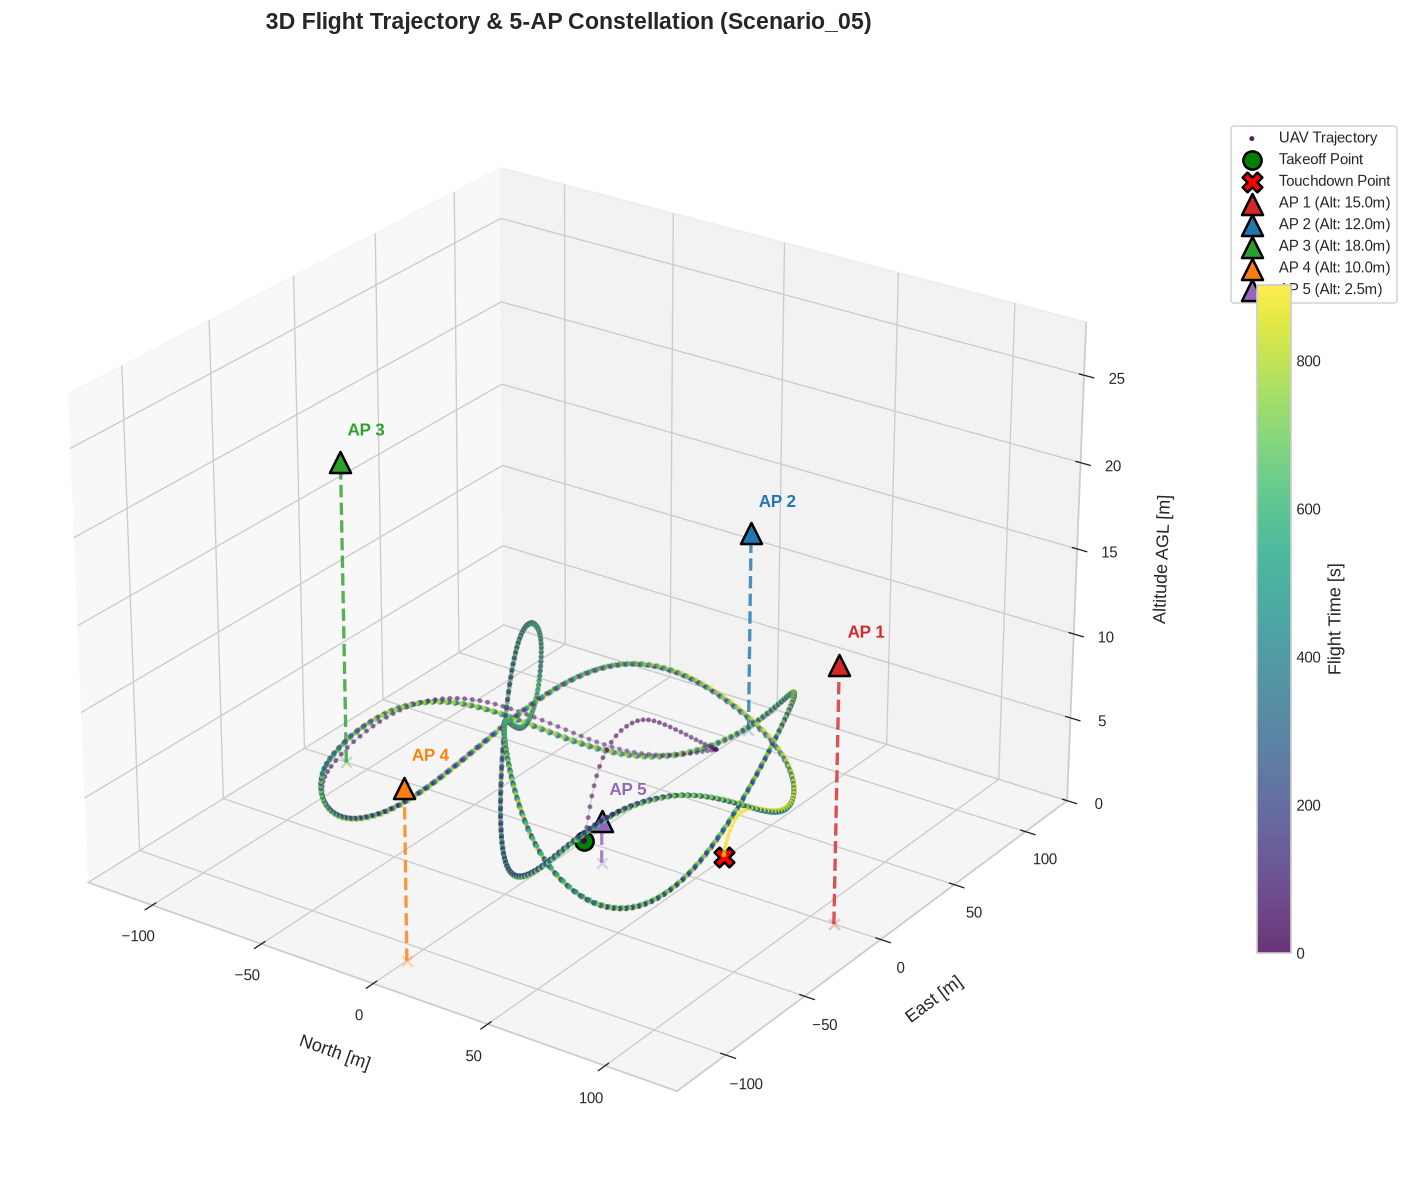

In [19]:
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# 1. Plot UAV Trajectory (Color-coded by flight time)
# Downsample slightly for smooth rendering if large
step = max(1, len(t) // 3000)
p = ax.scatter(
    pos_gt[::step, 0],
    pos_gt[::step, 1],
    alt_gt[::step],
    c=t[::step],
    cmap='viridis',
    s=4,
    alpha=0.8,
    label='UAV Trajectory'
)
cbar = fig.colorbar(p, ax=ax, pad=0.08, shrink=0.6)
cbar.set_label('Flight Time [s]')

# Trajectory Line
ax.plot(pos_gt[::step, 0], pos_gt[::step, 1], alt_gt[::step], color='gray', alpha=0.3, linewidth=0.8)

# 2. Mark Takeoff and Touchdown
ax.scatter(pos_gt[0, 0], pos_gt[0, 1], alt_gt[0], color='green', s=120, marker='o', edgecolors='black', linewidth=1.5, label='Takeoff Point', zorder=10)
ax.scatter(pos_gt[-1, 0], pos_gt[-1, 1], alt_gt[-1], color='red', s=140, marker='X', edgecolors='black', linewidth=1.5, label='Touchdown Point', zorder=10)

# 3. Plot 5 Ground Access Points with Elevation Masts
ap_colors = ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd']
for i in range(5):
    ap_n = ap_positions[i, 0]
    ap_e = ap_positions[i, 1]
    ap_alt = -ap_positions[i, 2]  # Elevation AGL
    col = ap_colors[i]

    # Ground mast line (Z=0 to AP altitude)
    ax.plot([ap_n, ap_n], [ap_e, ap_e], [0, ap_alt], color=col, linestyle='--', linewidth=2.0, alpha=0.8)

    # Anchor point
    ax.scatter(ap_n, ap_e, ap_alt, color=col, s=160, marker='^', edgecolors='black', linewidth=1.5, label=f'AP {i+1} (Alt: {ap_alt:.1f}m)', zorder=10)

    # Ground footprint marker
    ax.scatter(ap_n, ap_e, 0, color=col, s=40, marker='x', alpha=0.5)

    # Text annotation
    ax.text(ap_n + 2, ap_e + 2, ap_alt + 1.5, f"AP {i+1}", fontsize=10, weight='bold', color=col)

# 4. Reference Ground Grid at Z=0
margin = 20
xlim = (np.min([np.min(pos_gt[:, 0]), np.min(ap_positions[:, 0])]) - margin,
        np.max([np.max(pos_gt[:, 0]), np.max(ap_positions[:, 0])]) + margin)
ylim = (np.min([np.min(pos_gt[:, 1]), np.min(ap_positions[:, 1])]) - margin,
        np.max([np.max(pos_gt[:, 1]), np.max(ap_positions[:, 1])]) + margin)

# Formatting
ax.set_title(f"3D Flight Trajectory & 5-AP Constellation ({meta_attrs.get('scenario_id', 'Scenario')})", fontsize=14, weight='bold', pad=20)
ax.set_xlabel("North [m]", labelpad=10)
ax.set_ylabel("East [m]", labelpad=10)
ax.set_zlabel("Altitude AGL [m]", labelpad=10)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_zlim(0, max(np.max(alt_gt), np.max(-ap_positions[:, 2])) + 10)
ax.view_init(elev=26, azim=-55)
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 0.95), frameon=True)

plt.tight_layout()
plt.show()


## 2. AP Profiles: True 3D Distance, Raw FTM & Raw RSSI

Below are **5 dedicated subplots** (one for each of the 5 ground Access Points).

Each subplot displays:
* **Continuous True 3D Distance ($d_{\text{true}}$ in meters, blue solid line)**: Calculated as $\|\mathbf{p}_{\text{uav}}(t) - \mathbf{p}_{\text{ap}, i}\|_2$ over the entire flight.
* **Raw FTM Distance Measurements ($\hat{d}$ in meters, orange dots)**: Synthesized 802.11mc/az ranging samples at active 20 ms slots ($\hat{d} = \frac{\text{RTT} \cdot c}{2}$), illustrating multipath positive delay bias and noise.
* **Raw RSSI (dBm, green dots/line on right secondary y-axis)**: Received signal strength showing free-space path loss and airframe shadowing.


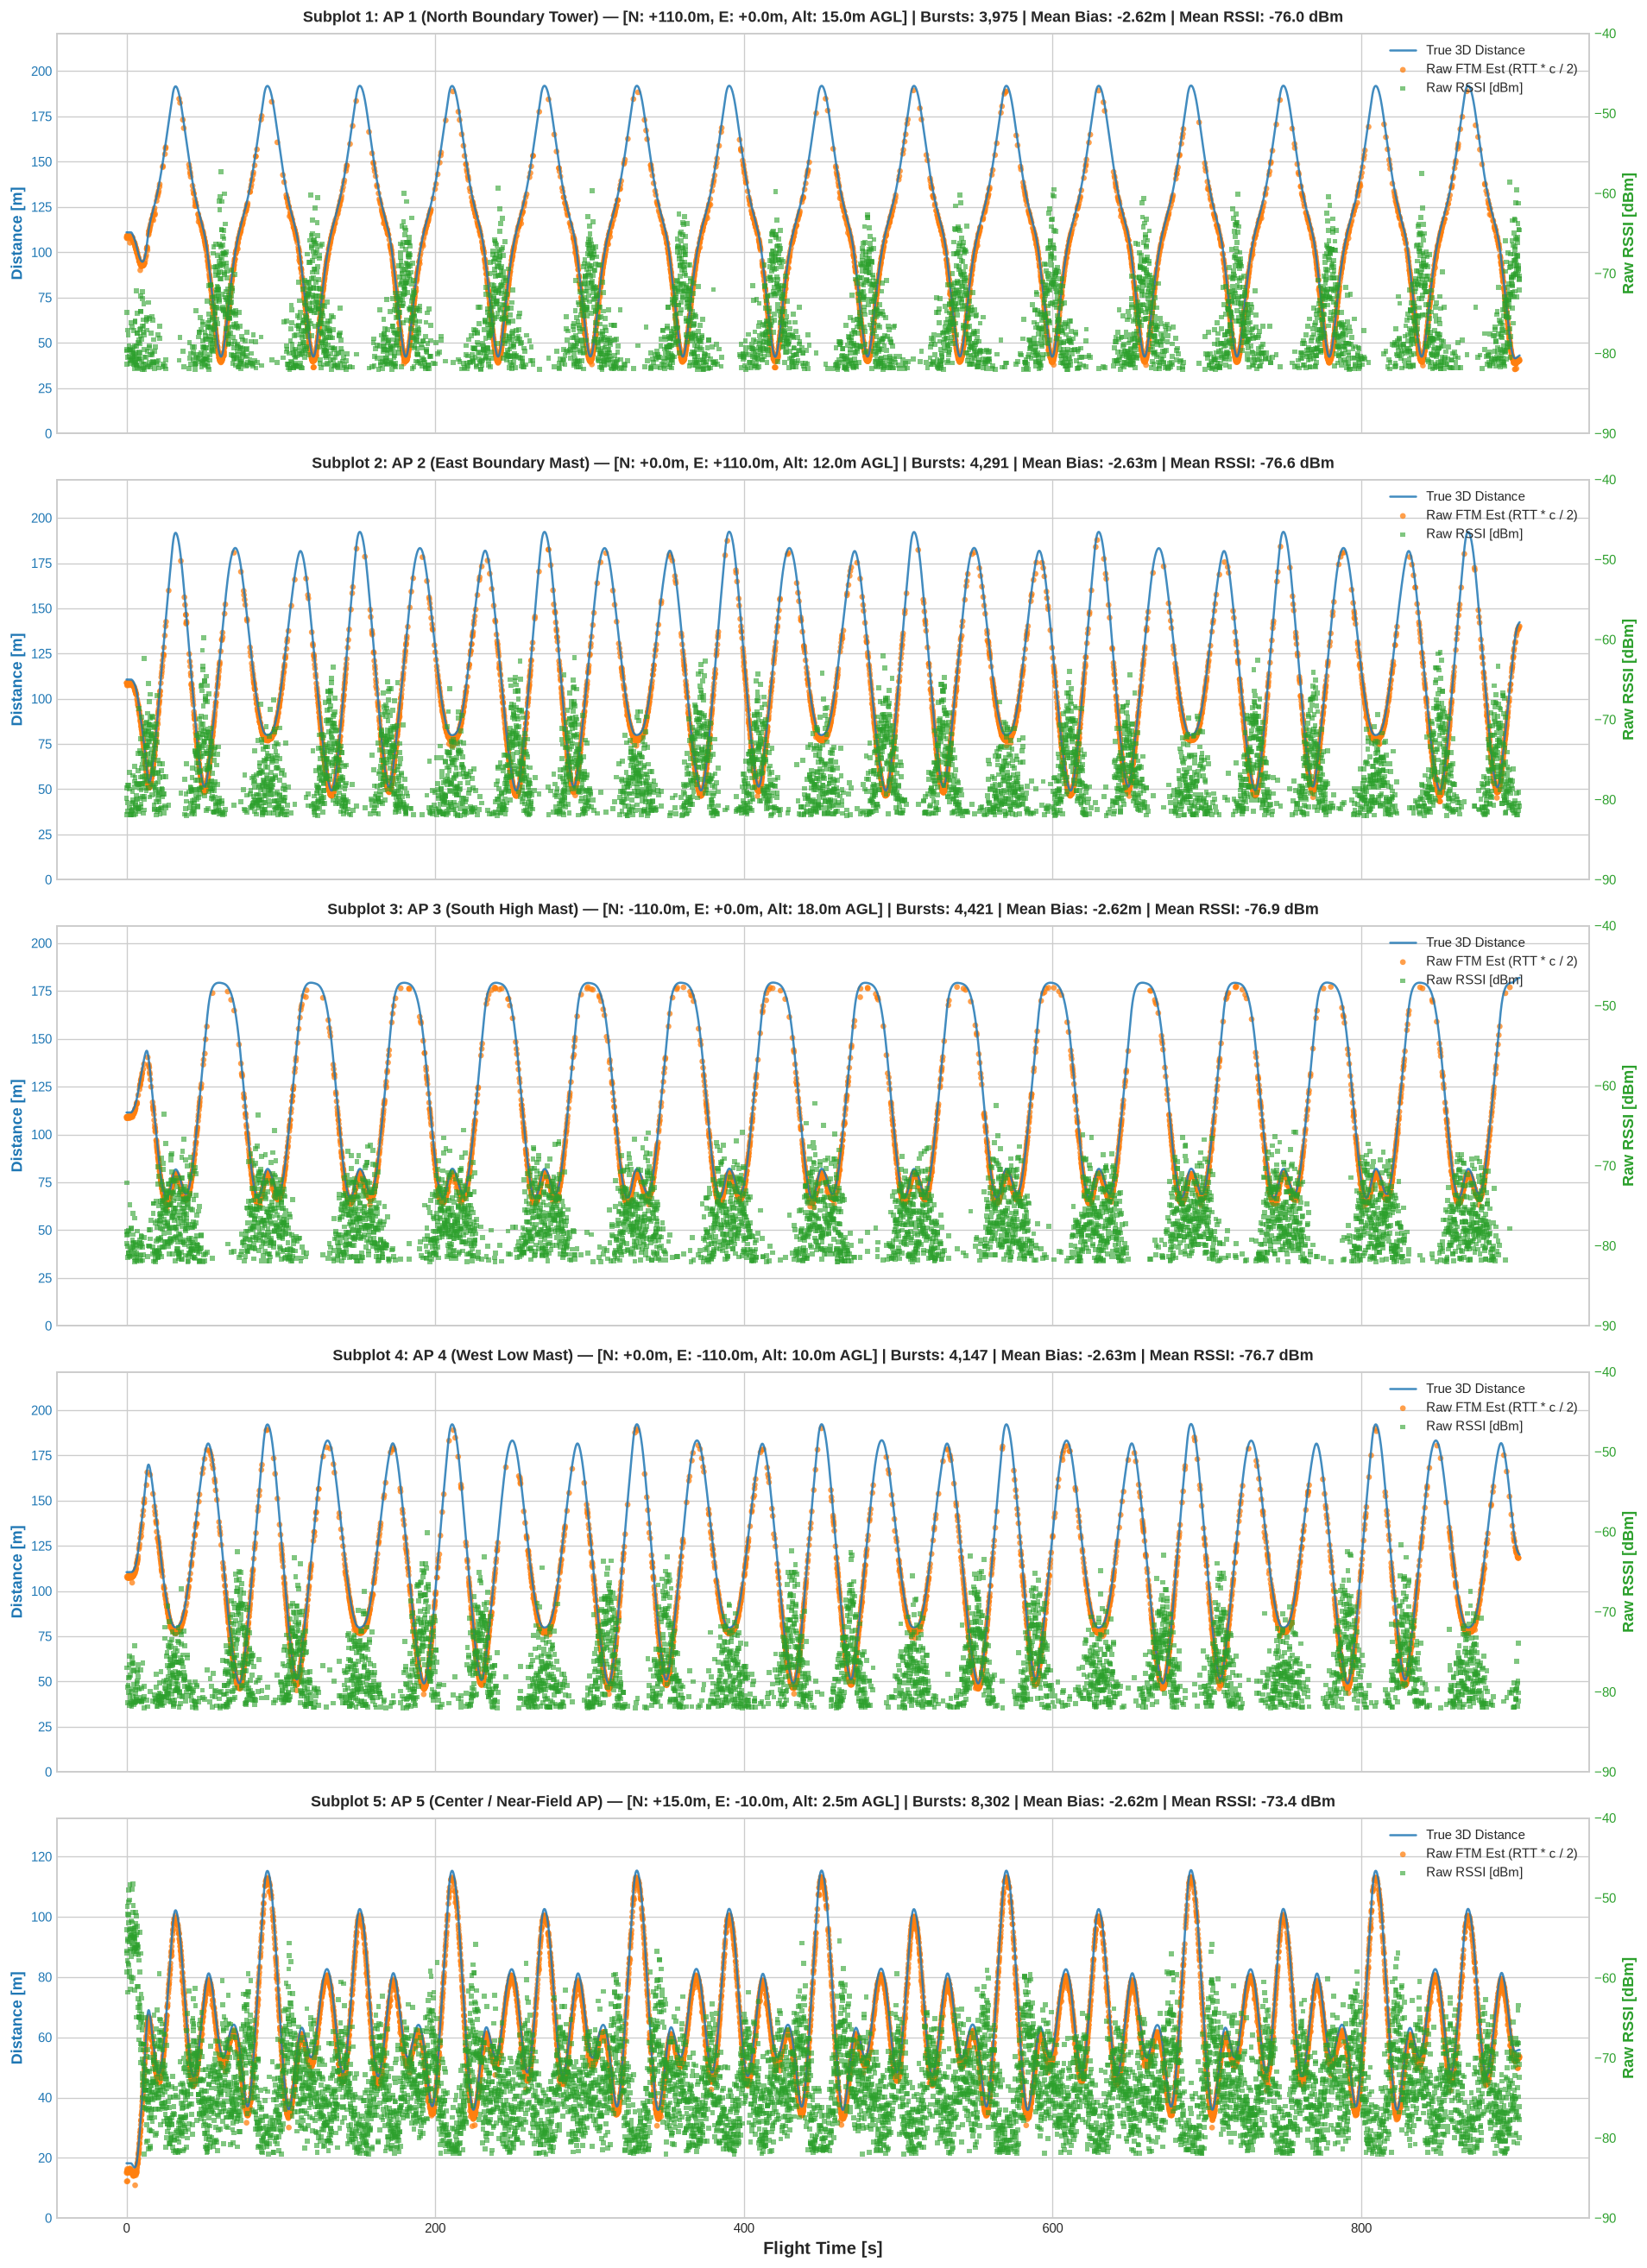

In [20]:
fig, axes = plt.subplots(5, 1, figsize=(16, 22), sharex=True)

ap_names = [f"AP {i+1}" for i in range(5)]
ap_descriptions = [
    "North Boundary Tower",
    "East Boundary Mast",
    "South High Mast",
    "West Low Mast",
    "Center / Near-Field AP"
]

for i in range(5):
    ax1 = axes[i]
    ap_idx = i + 1
    ap_pos = ap_positions[i]  # [North, East, Down]

    # 1. Compute continuous true 3D Euclidean distance for this AP
    diff_xyz = pos_gt - ap_pos
    dist_true_cont = np.linalg.norm(diff_xyz, axis=1)

    # 2. Extract valid Wi-Fi burst measurements for this AP
    mask_ap = (active_ap == ap_idx) & valid_flag
    t_bursts = t[mask_ap]
    ftm_est_bursts = ftm_est_dist[mask_ap]
    ftm_true_bursts = ftm_true_dist[mask_ap]
    rssi_bursts = rssi_dbm[mask_ap]
    los_bursts = is_los[mask_ap]

    # 3. Plot Distance (Left Y-Axis)
    # Continuous true distance curve
    line_true = ax1.plot(
        t, dist_true_cont,
        color='#1f77b4', linestyle='-', linewidth=1.5, alpha=0.85,
        label='True 3D Distance'
    )

    # Raw FTM distance measurements (scatter)
    scatter_ftm = ax1.scatter(
        t_bursts, ftm_est_bursts,
        color='#ff7f0e', s=16, alpha=0.75, marker='o', edgecolors='none',
        label='Raw FTM Est (RTT * c / 2)'
    )

    ax1.set_ylabel("Distance [m]", color='#1f77b4', fontsize=11, weight='bold')
    ax1.tick_params(axis='y', labelcolor='#1f77b4')
    ax1.set_ylim(0, np.max(dist_true_cont) * 1.15)

    # 4. Plot Raw RSSI (Right Secondary Y-Axis)
    ax2 = ax1.twinx()
    scatter_rssi = ax2.scatter(
        t_bursts, rssi_bursts,
        color='#2ca02c', s=12, alpha=0.6, marker='s', edgecolors='none',
        label='Raw RSSI [dBm]'
    )
    ax2.set_ylabel("Raw RSSI [dBm]", color='#2ca02c', fontsize=11, weight='bold')
    ax2.tick_params(axis='y', labelcolor='#2ca02c')
    ax2.set_ylim(-90, -40)
    ax2.grid(False)  # Avoid conflicting grid lines

    # 5. Title & Metadata Header
    pos_str = f"N: {ap_pos[0]:+.1f}m, E: {ap_pos[1]:+.1f}m, Alt: {-ap_pos[2]:.1f}m AGL"
    stats_str = f"Bursts: {len(t_bursts):,} | Mean Bias: {np.mean(ftm_est_bursts - ftm_true_bursts):+.2f}m | Mean RSSI: {np.mean(rssi_bursts):.1f} dBm"
    ax1.set_title(f"Subplot {i+1}: {ap_names[i]} ({ap_descriptions[i]}) — [{pos_str}] | {stats_str}", fontsize=11, weight='bold', pad=8)

    # Combined legend
    handles = [line_true[0], scatter_ftm, scatter_rssi]
    labels = [h.get_label() for h in handles]
    ax1.legend(handles, labels, loc='upper right', framealpha=0.9)

axes[-1].set_xlabel("Flight Time [s]", fontsize=12, weight='bold')
plt.tight_layout()
plt.show()


## 3. Quantitative Wi-Fi Ranging Statistics & Error Residuals

Here we analyze the measurement quality per Access Point:
* **FTM Ranging Error**: $\epsilon(t) = \hat{d}(t) - d_{\text{true}}(t)$
* **RMSE**: $\sqrt{\frac{1}{M}\sum \epsilon^2}$
* **Multipath Delay Bias**: Leading-edge ToA delay caused by non-line-of-sight and ground multipath reflections.


In [21]:
stats_records = []

for i in range(5):
    ap_idx = i + 1
    mask_ap = (active_ap == ap_idx) & valid_flag

    if np.sum(mask_ap) == 0:
        continue

    d_est = ftm_est_dist[mask_ap]
    d_true = ftm_true_dist[mask_ap]
    errors = d_est - d_true
    rssi_vals = rssi_dbm[mask_ap]
    los_vals = is_los[mask_ap]

    stats_records.append({
        "AP": f"AP {ap_idx}",
        "Position (N, E, Alt)": f"[{ap_positions[i, 0]:.0f}, {ap_positions[i, 1]:.0f}, {-ap_positions[i, 2]:.0f}]",
        "Valid Bursts": int(np.sum(mask_ap)),
        "Mean Error [m]": f"{np.mean(errors):+.3f}",
        "Std Dev [m]": f"{np.std(errors):.3f}",
        "RMSE [m]": f"{np.sqrt(np.mean(errors**2)):.3f}",
        "Max Error [m]": f"{np.max(np.abs(errors)):.2f}",
        "Mean RSSI [dBm]": f"{np.mean(rssi_vals):.1f}",
        "Min RSSI [dBm]": f"{np.min(rssi_vals):.1f}",
        "Max RSSI [dBm]": f"{np.max(rssi_vals):.1f}",
        "LOS Rate %": f"{(np.mean(los_vals) * 100):.1f}%"
    })

df_stats = pd.DataFrame(stats_records)
print("=== Wi-Fi FTM & RSSI Statistics by Access Point ===")
df_stats


=== Wi-Fi FTM & RSSI Statistics by Access Point ===


,AP,"Position (N, E, Alt)",Valid Bursts,Mean Error [m],Std Dev [m],RMSE [m],Max Error [m],Mean RSSI [dBm],Min RSSI [dBm],Max RSSI [dBm],LOS Rate %
0,AP 1,"[110, 0, 15]",3975,-2.615,0.637,2.692,6.07,-76.0,-82.0,-57.3,100.0%
1,AP 2,"[0, 110, 12]",4291,-2.627,0.613,2.698,6.07,-76.6,-82.0,-59.8,100.0%
2,AP 3,"[-110, 0, 18]",4421,-2.617,0.619,2.689,6.08,-76.9,-82.0,-62.2,100.0%
3,AP 4,"[0, -110, 10]",4147,-2.630,0.647,2.708,6.08,-76.7,-82.0,-60.1,100.0%
4,AP 5,"[15, -10, 2]",8302,-2.615,0.612,2.686,6.08,-73.4,-82.0,-48.2,100.0%


<>:10: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:10: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/tmp/ipykernel_61125/2800201443.py:10: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  axes[0].set_title("FTM Ranging Error Distribution ($\hat{d} - d_{\mathrm{true}}$)", fontsize=12, weight='bold')


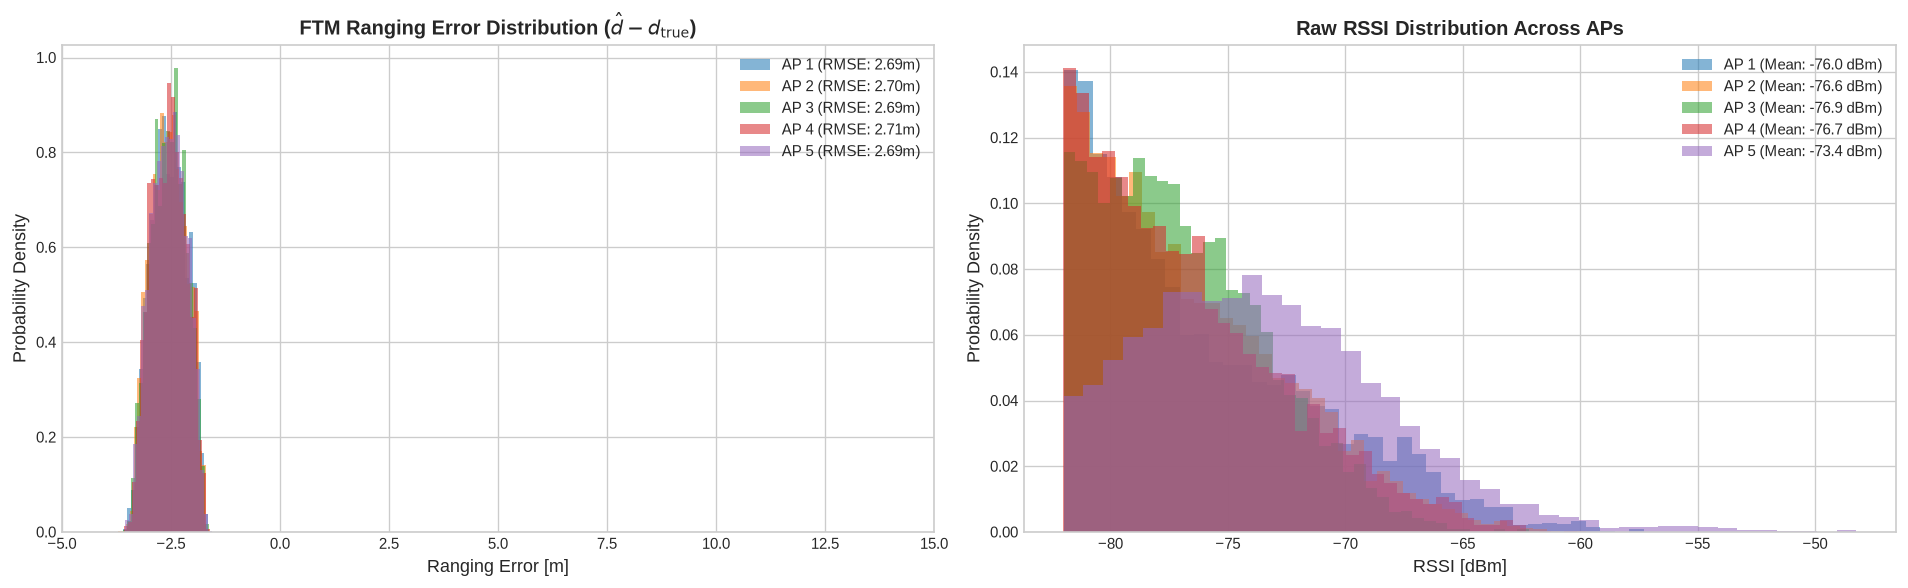

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: FTM Ranging Error Histograms
for i in range(5):
    ap_idx = i + 1
    mask_ap = (active_ap == ap_idx) & valid_flag
    err = ftm_est_dist[mask_ap] - ftm_true_dist[mask_ap]
    axes[0].hist(err, bins=50, alpha=0.55, label=f"AP {ap_idx} (RMSE: {np.sqrt(np.mean(err**2)):.2f}m)", density=True)

axes[0].set_title("FTM Ranging Error Distribution ($\hat{d} - d_{\mathrm{true}}$)", fontsize=12, weight='bold')
axes[0].set_xlabel("Ranging Error [m]")
axes[0].set_ylabel("Probability Density")
axes[0].set_xlim(-5, 15)
axes[0].legend()

# Plot 2: RSSI Distributions
for i in range(5):
    ap_idx = i + 1
    mask_ap = (active_ap == ap_idx) & valid_flag
    rssi_vals = rssi_dbm[mask_ap]
    axes[1].hist(rssi_vals, bins=40, alpha=0.55, label=f"AP {ap_idx} (Mean: {np.mean(rssi_vals):.1f} dBm)", density=True)

axes[1].set_title("Raw RSSI Distribution Across APs", fontsize=12, weight='bold')
axes[1].set_xlabel("RSSI [dBm]")
axes[1].set_ylabel("Probability Density")
axes[1].legend()

plt.tight_layout()
plt.show()
